# 04 · Definición del target
**Pregunta:** ¿el modelo debe predecir `total_transactions`, `amount_total` o `units_sold`?

**Estructura:**
1. Comparación de las variables candidatas (completitud, consistencia, artefactos, ruido).
2. Estabilidad del precio unitario: la condición que hace válida la derivación de unidades.
3. Experimento: unidades con un modelo directo vs. unidades derivadas del monto.
4. Sensibilidad: qué pasa si el precio deja de ser estable.
5. Decisión, supuestos y monitoreo.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
%config InlineBackend.figure_format = 'retina'

from scipy.stats import linregress
from src.data.load import load_transactions, load_stores, load_calendar
from src.data.preprocess import build_panel
from src.features.engineering import FeatureConfig, build_features
from src.features.targets import unit_price_by_series, derive_units, price_index_by_category
from src.models.backtest import FOLDS
from src.models.evaluate import wape, mape, bias, summarize
plt.rcParams.update({'figure.figsize': (10, 3.4), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 140, 'display.max_columns', 30, 'display.float_format', '{:,.3f}'.format)
t, s, c = load_transactions(), load_stores(), load_calendar()
p = build_panel(t, s, c)
d = p[~p.is_missing_row].copy()
d['paid'] = d.cash_transactions + d.card_transactions          # transacciones pagadas (efectivo + tarjeta)
d['price'] = d.amount_total / d.units_sold
print(f'{len(d):,} filas observadas')

203,958 filas observadas


## 1. Las variables candidatas
### 1.1 Completitud y consistencia

In [2]:
cmp_ = d.dropna(subset=['paid'])
chk = pd.DataFrame({
    '% nulos': [d.amount_total.isna().mean() * 100, d.units_sold.isna().mean() * 100, d.total_transactions.isna().mean() * 100],
    'consistencia': ['= efectivo + tarjeta (diferencia máx. %.0e MXN)' % (d.amount_total - d.amount_cash - d.amount_card).abs().max(),
                     'unidades por transacción pagada entre %.2f y %.2f (plausible)' % ((d.units_sold / d.paid).min(), (d.units_sold / d.paid).max()),
                     '≠ efectivo + tarjeta en %.1f%% de las filas (todas con promoción)' % ((cmp_.total_transactions != cmp_.paid).mean() * 100)]},
    index=['amount_total', 'units_sold', 'total_transactions']); chk

,% nulos,consistencia
amount_total,0.000,= efectivo + tarjeta (diferencia máx. 3e-10 MXN)
units_sold,3.000,unidades por transacción pagada entre 1.18 y 2...
total_transactions,0.000,≠ efectivo + tarjeta en 20.0% de las filas (to...


### 1.2 Efecto aparente de la promoción en cada variable
Diferencia de la media del log (centrado por serie) entre filas con y sin promoción, con IC 95 %. Si una variable sube con la promoción pero el dinero cobrado no, esa subida no es demanda real.

In [3]:
rows = {}
for col, name in [('amount_total', 'amount_total'), ('units_sold', 'units_sold'), ('paid', 'efectivo + tarjeta'), ('total_transactions', 'total_transactions')]:
    l = np.log(d[col]); lc = l - l.groupby([d.store_id, d.category]).transform('mean')
    a, b = lc[(d.has_promotion == 1) & lc.notna()], lc[(d.has_promotion == 0) & lc.notna()]
    eff = a.mean() - b.mean(); se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    rows[name] = {'efecto promoción %': np.expm1(eff) * 100, 'IC95% inf': np.expm1(eff - 1.96 * se) * 100, 'IC95% sup': np.expm1(eff + 1.96 * se) * 100}
PE = pd.DataFrame(rows).T; PE.round(2)

,efecto promoción %,IC95% inf,IC95% sup
amount_total,0.030,-0.410,0.480
units_sold,0.310,-0.190,0.820
efectivo + tarjeta,0.090,-0.350,0.520
total_transactions,22.150,21.630,22.670


### 1.3 Ruido de cada variable y piso de error
Ruido = desviación estándar del log de la variable en días normales, tras quitar nivel de serie, día de la semana, quincena y nivel mensual. El **piso** es el WAPE/MAPE de un pronóstico *perfecto* del valor esperado si ese ruido es independiente (simulación lognormal).

In [4]:
n = d[~(d.is_official_holiday | d.is_buen_fin | d.is_navidad_season)].dropna(subset=['amount_total', 'units_sold', 'paid', 'total_transactions', 'price']).copy()
n['ym'] = n.date.dt.to_period('M'); key = [n.store_id, n.category]; R = {}
for col in ['amount_total', 'units_sold', 'paid', 'total_transactions', 'price']:
    l = np.log(n[col]); l = l - l.groupby(key).transform('mean')
    l = l - l.groupby(key + [n.day_of_week]).transform('mean'); l = l - l.groupby(key + [n.is_payday]).transform('mean')
    R[col] = l - l.groupby(key + [n.ym]).transform('mean')
R = pd.DataFrame(R); sig = R.std(); z = np.random.default_rng(1).standard_normal(1_000_000)
def floor(sg):
    y = 100 * np.exp(sg * z); return wape(y, np.full_like(y, 100.0)), mape(y, np.full_like(y, 100.0))
F = pd.DataFrame({k: {'σ del ruido': sig[k], 'piso WAPE %': floor(sig[k])[0] * 100, 'piso MAPE %': floor(sig[k])[1] * 100} for k in sig.index}).T
print(f'Filas comparables: {len(R):,} (días normales, sin nulos en ninguna variable)'); F.rename(index={'paid': 'efectivo + tarjeta', 'price': 'precio efectivo diario'})

Filas comparables: 167,687 (días normales, sin nulos en ninguna variable)


,σ del ruido,piso WAPE %,piso MAPE %
amount_total,0.192,15.224,15.509
units_sold,0.277,21.803,22.659
efectivo + tarjeta,0.151,11.985,12.123
total_transactions,0.172,13.589,13.791
precio efectivo diario,0.261,20.560,21.274


### 1.4 Scorecard

In [5]:
sc = pd.DataFrame({
    '% nulos': [d[k].isna().mean() * 100 for k in ['amount_total', 'units_sold', 'total_transactions']],
    'efecto aparente de la promoción %': PE.loc[['amount_total', 'units_sold', 'total_transactions'], 'efecto promoción %'].values,
    'σ ruido': sig[['amount_total', 'units_sold', 'total_transactions']].values,
    'piso WAPE %': [floor(sig[k])[0] * 100 for k in ['amount_total', 'units_sold', 'total_transactions']]},
    index=['amount_total', 'units_sold', 'total_transactions'])
sc['veredicto'] = ['TARGET', 'derivar del monto', 'no pronosticar (artefacto de promoción)']; sc

,% nulos,efecto aparente de la promoción %,σ ruido,piso WAPE %,veredicto
amount_total,0.000,0.033,0.192,15.224,TARGET
units_sold,3.000,0.310,0.277,21.803,derivar del monto
total_transactions,0.000,22.148,0.172,13.589,no pronosticar (artefacto de promoción)


**Lectura.**
- **`amount_total`:** sin nulos, consistente con sus componentes y **sin efecto aparente de la promoción** (+0.03 %, IC 95 % de −0.4 % a +0.5 %).
- **`units_sold`:** 3 % de nulos y más ruidosa (σ = 0.28 frente a 0.19), lo que fija un piso de WAPE de ≈ 22 % contra ≈ 15 % del monto. Tampoco muestra efecto de promoción (+0.3 %, IC 95 % de −0.2 % a +0.8 %).
- **`total_transactions`:** parece subir **22 %** con la promoción (IC 95 % de 21.6 % a 22.7 %), pero el dinero cobrado y las transacciones pagadas (+0.1 %) no se mueven: es el artefacto descrito en los notebooks 01 y 02. Pronosticarla significaría aprender un defecto de captura.
- **Efectivo + tarjeta** es la menos ruidosa (σ = 0.15), pero tiene 6 % de nulos (por el efectivo), mide tráfico y no la venta que consumen finanzas e inventario. Que una variable sea más fácil de predecir no la hace más útil para el negocio: los errores **no son comparables entre variables**.

**Conclusión:** `amount_total` es la única candidata completa, consistente, sin artefactos y alineada con el uplift de la Fase 4, que también se mide sobre el monto.

## 2. Estabilidad del precio unitario
La derivación `unidades = monto ÷ precio` solo es válida si el precio por unidad de cada serie es **estable**: no cambia con el tiempo, con la promoción ni con los eventos. Precio = `amount_total / units_sold`, normalizado por el precio medio de cada serie.

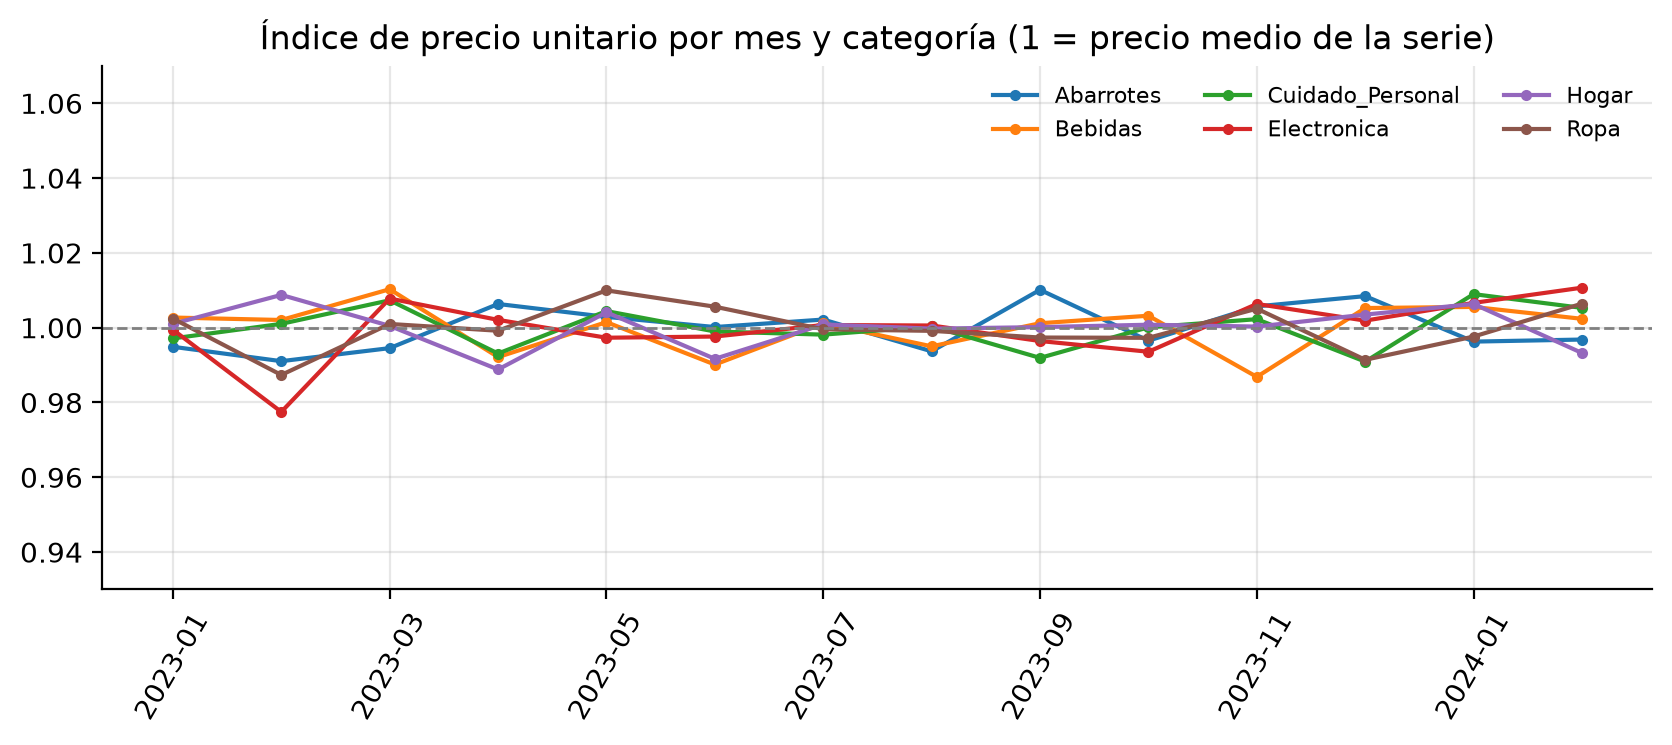

,pendiente % por mes,p-valor,variación acumulada 14 meses %,desv. máx. mensual vs 1 %,error estándar mensual %
Abarrotes,0.042,0.307,0.551,1.012,0.570
Bebidas,-0.003,0.951,-0.037,1.315,0.572
Cuidado_Personal,0.015,0.693,0.199,0.908,0.568
Electronica,0.093,0.082,1.203,2.252,0.568
Hogar,-0.003,0.941,-0.037,1.118,0.569
Ropa,0.007,0.870,0.089,1.264,0.567


In [6]:
idx = price_index_by_category(p)
ax = idx.plot(marker='o', ms=3, title='Índice de precio unitario por mes y categoría (1 = precio medio de la serie)'); ax.axhline(1, color='gray', ls='--', lw=1); ax.set_ylim(0.93, 1.07); ax.set_xlabel(''); plt.xticks(rotation=60); plt.legend(ncol=3, fontsize=8, frameon=False); plt.show()
dd = d.dropna(subset=['price']).copy(); dd['p_idx'] = dd.price / dd.groupby(['store_id', 'category']).price.transform('mean'); dd['mes'] = dd.date.dt.to_period('M').astype(str)
se_m = (dd.groupby(['category', 'mes']).p_idx.std() / np.sqrt(dd.groupby(['category', 'mes']).p_idx.size())).groupby('category').mean()
tr = {}
for k in idx.columns:
    lr = linregress(np.arange(len(idx)), idx[k].values)
    tr[k] = {'pendiente % por mes': lr.slope * 100, 'p-valor': lr.pvalue, 'variación acumulada 14 meses %': lr.slope * 13 * 100, 'desv. máx. mensual vs 1 %': (idx[k] - 1).abs().max() * 100, 'error estándar mensual %': se_m[k] * 100}
pd.DataFrame(tr).T.round(3)

In [7]:
ev = np.where(dd.is_buen_fin, 'Buen Fin', np.where(dd.is_navidad_season, 'temporada navideña', np.where(dd.is_official_holiday, 'festivo', 'día normal')))
tab = pd.concat({'promoción': dd.groupby(dd.has_promotion.map({0: 'sin promoción', 1: 'con promoción'})).p_idx.mean(), 'formato': dd.groupby('store_format').p_idx.mean(),
                 'evento': dd.groupby(ev).p_idx.mean(), 'día de la semana': dd.groupby(dd.day_of_week.map(dict(enumerate(['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom'])))).p_idx.mean()})
print('Índice de precio medio por grupo (1.000 = sin diferencia):'); print(tab.round(4).to_string())
ps = unit_price_by_series(p).reset_index(); cv = ps.groupby('category').unit_price.agg(['mean', 'std', 'min', 'max']); cv['CV entre tiendas'] = cv['std'] / cv['mean']
print('\nPrecio unitario por serie: dispersión entre las 80 tiendas, por categoría (MXN):'); cv.round(3)

Índice de precio medio por grupo (1.000 = sin diferencia):
promoción         con promoción        0.998
                  sin promoción        1.001
formato           Bodega               1.000
                  Express              1.000
                  Supercenter          1.000
evento            Buen Fin             1.007
                  día normal           1.000
                  festivo              1.002
                  temporada navideña   0.996
día de la semana  dom                  1.000
                  jue                  0.999
                  lun                  0.999
                  mar                  0.998
                  mié                  1.001
                  sáb                  1.002
                  vie                  1.002

Precio unitario por serie: dispersión entre las 80 tiendas, por categoría (MXN):


,mean,std,min,max,CV entre tiendas
category,,,,,
Abarrotes,113.300,19.536,90.769,163.479,0.172
Bebidas,74.548,12.636,60.138,109.358,0.170
Cuidado_Personal,95.324,16.112,76.884,136.758,0.169
Electronica,489.546,83.440,391.540,698.670,0.170
Hogar,196.130,32.894,158.413,285.411,0.168
Ropa,267.539,45.532,214.132,382.941,0.170


In [8]:
va, vp, vu = R.amount_total.var(), R.price.var(), R.units_sold.var(); cov = np.cov(R.amount_total, R.price)[0, 1]
pd.DataFrame({'valor': {'var(log monto)': va, 'var(log precio efectivo diario)': vp, '2·cov(monto, precio)': 2 * cov, 'var(monto)+var(precio)−2·cov': va + vp - 2 * cov, 'var(log unidades) observada': vu}}).round(4)

,valor
var(log monto),0.037
var(log precio efectivo diario),0.068
"2·cov(monto, precio)",0.028
var(monto)+var(precio)−2·cov,0.077
var(log unidades) observada,0.077


**Lectura.**
- **Estable en el tiempo.** Ninguna categoría tiene tendencia significativa (p entre 0.08 y 0.95; variación acumulada entre −0.04 % y +1.2 % en 14 meses). Electrónica (+1.2 %, p = 0.08) es la única a vigilar. Las desviaciones mensuales máximas son ≤ 2.3 %, frente a un error estándar de 0.57 %.
- **Estable ante promociones y eventos.** Con promoción 0.998 vs. 1.001 sin ella: las promociones **no bajan el precio**. Formato 1.000, Buen Fin 1.007, festivos 1.002, temporada navideña 0.996, día de la semana ±0.2 %.
- **Pero no es el mismo precio en todas las tiendas:** dentro de cada categoría el precio unitario varía ≈ 17 % entre tiendas (CV 0.17), así que la derivación debe usar el precio **de la serie** (tienda × categoría) y no el de la categoría.
- **El precio efectivo diario es muy ruidoso** (σ = 0.26). Como `log(unidades) = log(monto) − log(precio)`, la varianza de las unidades suma la del monto (0.037) y la del precio efectivo (0.068) menos 2·cov (0.028) = 0.077: por eso las unidades tienen un error irreducible mayor que el monto, aunque su nivel promedio sea predecible.

## 3. Experimento: unidades directas vs. derivadas del monto
Mismo esquema directo de horizonte 14 días que el resto del proyecto (`FeatureConfig`), tres folds (`sep_2023` regular, `buen_fin_2023` evento y `feb_2024` regular) y entrenamiento hasta 14 días antes de cada fold. LightGBM sobre log del target.
- **Directo:** modelo que predice `units_sold` con sus propios rezagos.
- **Derivado, precio de la serie:** monto pronosticado ÷ precio de la tienda × categoría (con datos hasta el corte).
- **Derivado, precio de la categoría:** un solo precio por categoría.
- **Derivado, precio de la serie (últimos 90 días).**

Las métricas de unidades se evalúan solo en filas con `units_sold` observado y a nivel tienda × categoría × día.

In [9]:
cfg = FeatureConfig(horizon=14); cfg_u = FeatureConfig(horizon=14, target='units_sold')
FA, FU = build_features(p, cfg), build_features(p, cfg_u)
assert (FA[['store_id', 'category', 'date']].values == FU[['store_id', 'category', 'date']].values).all()
PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, random_state=0, verbose=-1)
cols = cfg.feature_columns(); sel = {f.name: f for f in FOLDS if f.name in ('sep_2023', 'buen_fin_2023', 'feb_2024')}
rows, preds = [], {}
for name, fold in sel.items():
    cut = fold.train_cutoff(cfg.horizon)
    trA = FA[(FA.date <= cut) & FA.eligible]; trU = FU[(FU.date <= cut) & FU.eligible]
    mA = lgb.LGBMRegressor(**PARAMS).fit(trA[cols], np.log(trA.y)); mU = lgb.LGBMRegressor(**PARAMS).fit(trU[cols], np.log(trU.y))
    te = FA.loc[fold.test_mask(FA.date) & FA.eligible, ['store_id', 'category', 'date']].copy(); ix = te.index
    te['amount_hat'] = np.exp(mA.predict(FA.loc[ix, cols])); te['units_direct'] = np.exp(mU.predict(FU.loc[ix, cols])); te['units'] = FU.loc[ix, 'y']
    p_ser = unit_price_by_series(p, cut); p_90 = unit_price_by_series(p, cut, last_days=90)
    sub = p[(p.date <= cut) & p.units_sold.notna() & ~p.is_missing_row]; p_cat = (sub.groupby('category').amount_total.sum() / sub.groupby('category').units_sold.sum())
    te['units_serie'] = derive_units(te, 'amount_hat', p_ser); te['units_serie90'] = derive_units(te, 'amount_hat', p_90)
    te['units_cat'] = te.amount_hat / te.category.map(p_cat).astype(float)
    obs_u = te[te.units.notna()]; preds[name] = obs_u
    for k, lab in [('units_direct', 'directo'), ('units_serie', 'derivado · precio de la serie'), ('units_serie90', 'derivado · precio serie 90 d'), ('units_cat', 'derivado · precio de la categoría')]:
        rows.append({'fold': name, 'unidades': lab, 'WAPE %': wape(obs_u.units, obs_u[k]) * 100, 'sesgo %': bias(obs_u.units, obs_u[k]) * 100})
    rows.append({'fold': name, 'unidades': '(monto: WAPE de amount_total)', 'WAPE %': wape(te.merge(FA[['store_id', 'category', 'date', 'y']], on=['store_id', 'category', 'date']).y, te.amount_hat) * 100, 'sesgo %': np.nan})
E = pd.DataFrame(rows); print('WAPE y sesgo a nivel tienda × categoría × día, horizonte 14 días:'); E.pivot(index='unidades', columns='fold', values='WAPE %').round(1).join(E.pivot(index='unidades', columns='fold', values='sesgo %').round(1), rsuffix=' (sesgo %)')

WAPE y sesgo a nivel tienda × categoría × día, horizonte 14 días:


fold,buen_fin_2023,feb_2024,sep_2023,buen_fin_2023 (sesgo %),feb_2024 (sesgo %),sep_2023 (sesgo %)
unidades,,,,,,
(monto: WAPE de amount_total),37.600,16.200,18.000,NaN,NaN,NaN
derivado · precio de la categoría,42.500,26.300,27.900,-33.400,-1.500,2.900
derivado · precio de la serie,40.900,23.200,24.800,-33.300,-1.400,2.900
derivado · precio serie 90 d,40.900,23.300,24.900,-33.300,-1.500,2.800
directo,41.600,23.300,24.600,-35.500,-3.400,-0.000


**Lectura.**
- **El precio de la serie es necesario.** Usar un precio único por categoría empeora las unidades ≈ 3 puntos de WAPE en los folds regulares (27.9 % vs. 24.8 % en septiembre; 26.3 % vs. 23.2 % en febrero) y 1.6 en el fold de Buen Fin.
- **Derivar es tan bueno como el modelo directo.** Las diferencias entre el modelo directo y las unidades derivadas con precio de la serie son de décimas de punto y de signo cambiante: directo 0.2 mejor en septiembre (24.6 % vs. 24.8 %), empate en febrero (23.3 % vs. 23.2 %) y derivado 0.7 mejor en el fold de Buen Fin (40.9 % vs. 41.6 %).
- **El sesgo se hereda del monto.** En Buen Fin ambos enfoques sub-pronostican ≈ −33 % a −35 % (el modelo nunca vio el evento); corregir el sesgo del monto corrige el de las unidades.
- Usar solo los últimos 90 días para el precio da lo mismo que toda la historia (24.9 % vs. 24.8 %): con precios estables no hace falta una ventana corta.
- Para referencia, el WAPE del monto a este mismo nivel es 18.0 % (septiembre) y 16.2 % (febrero), cerca del piso de ruido de 15.2 %. Las unidades se reportan con sus propias métricas y su propio piso (≈ 21.8 %).

*Nota:* las métricas de unidades se evalúan a nivel serie-día solo donde existe `units_sold`; a nivel semanal habría que descartar casi todas las semanas, porque un 3 % de nulos deja pocas series-semana con los 7 días.

## 4. Sensibilidad: ¿qué pasa si el precio deja de ser estable?
Se simula que en el periodo pronosticado el precio real de todas las series se desvía δ % del precio histórico usado en la derivación (fold `feb_2024`). Si el precio real sube δ %, el mismo monto compra δ % menos unidades y las unidades derivadas quedan sesgadas ≈ +δ.

In [10]:
u = preds['feb_2024']; rows = []
for dl in [-0.10, -0.05, -0.02, 0.0, 0.02, 0.05, 0.10]:
    yy = u.units / (1 + dl); r_ = summarize(yy, u.units_serie); rows.append({'deriva del precio δ': f'{dl:+.0%}', 'WAPE %': r_['wape'] * 100, 'sesgo %': r_['bias'] * 100})
pd.DataFrame(rows).set_index('deriva del precio δ').round(1)

,WAPE %,sesgo %
deriva del precio δ,,
-10%,24.100,-11.200
-5%,23.400,-6.300
-2%,23.200,-3.300
+0%,23.200,-1.400
+2%,23.400,0.600
+5%,23.700,3.600
+10%,24.600,8.500


**Lectura.** La derivación falla solo por **sesgo**, no por error: si el precio real se desvía δ % del histórico, el sesgo de las unidades se mueve ≈ δ puntos (−1.4 % con δ = 0, +3.6 % con +5 %, +8.5 % con +10 %). El WAPE casi no cambia con |δ| ≤ 5 % (23.2 %–23.7 %) y sube a 24.6 % con +10 %. Con los precios observados (sin tendencia y con error estándar mensual de 0.57 %) no es un riesgo hoy, pero en producción hay que vigilarlo.

**Regla de monitoreo propuesta.** Recalcular cada mes el índice de precio por categoría (`price_index_by_category`) y alertar si se aleja **±3 %** del precio usado en la derivación (≈ 5 veces el error estándar mensual observado). Si el supuesto se rompe, usar el modelo directo de unidades.

## Decisión
**El modelo se entrena sobre `amount_total` y las unidades vendidas se derivan:**

`unidades pronosticadas = monto pronosticado ÷ precio unitario de la serie (tienda × categoría)`

con precio unitario = `Σ monto ÷ Σ unidades` de la historia disponible al momento del pronóstico, solo con filas que tienen unidades observadas (`src/features/targets.py`). **`total_transactions` no se pronostica.**

| Criterio | `amount_total` | `units_sold` | `total_transactions` |
|---|---|---|---|
| Completitud | 0 % nulos | 3 % nulos | 0 % nulos |
| Consistencia | suma exacta de efectivo + tarjeta | plausible | **inflada en el 100 % de las filas con promoción** |
| Efecto aparente de la promoción | +0.03 % (nulo) | +0.3 % (nulo) | **+22 %** (artefacto) |
| Piso de error (WAPE serie-día) | ≈ 15 % | ≈ 22 % | ≈ 14 % |
| Alineación con la Fase 4 (uplift) | misma variable | requeriría otra | no válida |

**Por qué es válido derivar las unidades:** el precio de cada serie es estable en el tiempo, no cambia con la promoción ni con los eventos; es heterogéneo entre tiendas (por eso debe ser por serie); se calcula solo con datos hasta el corte (sin fuga); y el costo medido frente a un modelo directo es de décimas de punto, sin ganador consistente.

**Supuestos y riesgos**
- Precio estable. Cierto en estos 14 meses; si cambia δ %, el sesgo de las unidades se mueve ≈ δ puntos.
- Las unidades derivadas heredan el sesgo del modelo de monto.
- Las unidades tienen un error irreducible mayor (el precio efectivo diario fluctúa σ ≈ 0.26): se reportan con sus propias métricas, sin compararlas con las del monto.

**Consecuencias para el proyecto**
- Los rezagos y medias móviles se calculan sobre `amount_total` (`FeatureConfig.target`).
- El uplift de la Fase 4 se mide sobre `amount_total`.
- El dashboard mostrará monto y unidades con métricas separadas y el índice de precio como indicador de calidad.